# Самостоятельная работа

1. Усложните модель LeNet или напишите свою модель с нуля.
2. Добавьте рассчёт train/val метрик.
3. Обучите модель на наборе данных [CIFAR-10](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html).
4. Возьмите более сложный датасет(желательно что бы он был как-то связан с транспортом).
5. Попробуйте обучить модель на нём
6. Посчитайте количество параметров вашей модели.
7. Визуализируйте loss и метрики
8. Визуализируйте карты признаков последнего слоя и попробуйте их интрерпретировать.
9. Проверьте финальное качество своей модели на test выборке.

In [20]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

import torchvision
from torchvision import datasets
from torchvision.transforms import v2 as transforms
from torchvision.utils import make_grid

In [7]:
def set_random_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_random_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используем устройство: {device}")

Используем устройство: cuda


## Модель

In [8]:
class SimpleCNN(nn.Module):
    """
    CNN с нуля: три сверточных блока (conv -> batchnorm -> relu -> maxpool).
    На каждом блоке число каналов растет вдвое, а пространственный размер
    падает вдвое за счет пулинга - стандартная схема из лекции. На выходе -
    две полносвязных слоя для классификации.
    """

    def __init__(self, num_classes, in_channels=3):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(2)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool3(x)

        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [9]:
def run_epoch(model, loader, criterion, optimizer=None, device="cpu"):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def fit(model, train_loader, val_loader, num_epochs, lr=1e-3, device="cpu"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(num_epochs):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, None, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Эпоха {epoch + 1}/{num_epochs}: "
              f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
              f"val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")

    return history


def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="val")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Эпоха")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="val")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Эпоха")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## CIFAR-10

In [10]:
transform = transforms.Compose([
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
])

cifar_train_full = datasets.CIFAR10(root="./CIFAR10", train=True, download=False, transform=transform)
cifar_test = datasets.CIFAR10(root="./CIFAR10", train=False, download=False, transform=transform)

print(f"Train+val: {len(cifar_train_full)}, test: {len(cifar_test)}")

Train+val: 50000, test: 10000


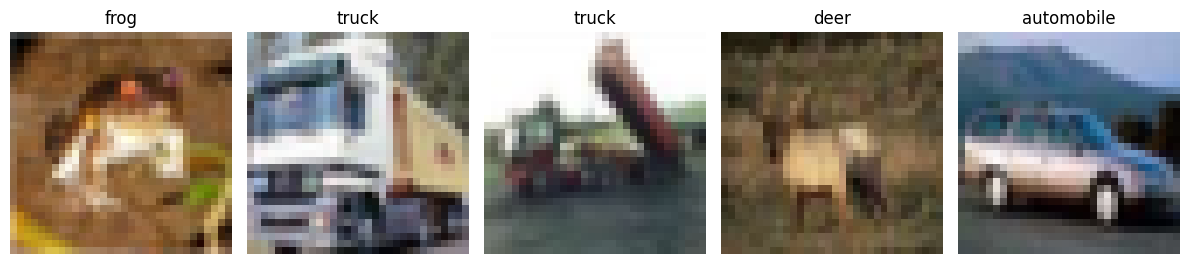

In [11]:
cifar_classes = cifar_train_full.classes

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    image, label = cifar_train_full[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(cifar_classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [12]:
cifar_train, cifar_val = random_split(cifar_train_full, [45000, 5000])

cifar_train_loader = DataLoader(cifar_train, batch_size=64, shuffle=True)
cifar_val_loader = DataLoader(cifar_val, batch_size=64, shuffle=False)
cifar_test_loader = DataLoader(cifar_test, batch_size=64, shuffle=False)

In [13]:
cifar_model = SimpleCNN(num_classes=10).to(device)
print(f"Количество параметров: {count_parameters(cifar_model)}")

Количество параметров: 620810


In [14]:
cifar_history = fit(cifar_model, cifar_train_loader, cifar_val_loader, num_epochs=15, lr=1e-3, device=device)

Эпоха 1/15: train_loss=1.4530, train_acc=0.4674, val_loss=1.2438, val_acc=0.5642
Эпоха 2/15: train_loss=1.1077, train_acc=0.6063, val_loss=1.0304, val_acc=0.6234
Эпоха 3/15: train_loss=0.9769, train_acc=0.6564, val_loss=1.2367, val_acc=0.5888
Эпоха 4/15: train_loss=0.8860, train_acc=0.6909, val_loss=0.8658, val_acc=0.6896
Эпоха 5/15: train_loss=0.8226, train_acc=0.7125, val_loss=1.6907, val_acc=0.5344
Эпоха 6/15: train_loss=0.7674, train_acc=0.7318, val_loss=0.7770, val_acc=0.7168
Эпоха 7/15: train_loss=0.7148, train_acc=0.7514, val_loss=0.8342, val_acc=0.7070
Эпоха 8/15: train_loss=0.6656, train_acc=0.7685, val_loss=0.7843, val_acc=0.7362
Эпоха 9/15: train_loss=0.6237, train_acc=0.7836, val_loss=0.6843, val_acc=0.7666
Эпоха 10/15: train_loss=0.5767, train_acc=0.8004, val_loss=0.6637, val_acc=0.7676
Эпоха 11/15: train_loss=0.5440, train_acc=0.8071, val_loss=0.7165, val_acc=0.7558
Эпоха 12/15: train_loss=0.5051, train_acc=0.8244, val_loss=0.6945, val_acc=0.7750
Эпоха 13/15: train_loss=0

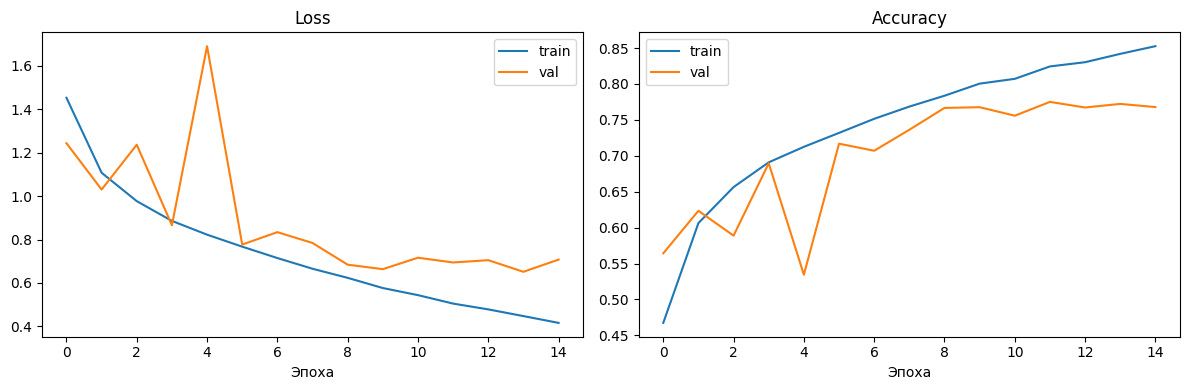

In [15]:
plot_history(cifar_history)

In [16]:
cifar_test_loss, cifar_test_acc = run_epoch(cifar_model, cifar_test_loader, nn.CrossEntropyLoss(), None, device)
print(f"Качество на test выборке: loss={cifar_test_loss:.4f}, accuracy={cifar_test_acc:.4f}")

Качество на test выборке: loss=0.7320, accuracy=0.7619


## GTSRB

Второй датасет - GTSRB (German Traffic Sign Recognition Benchmark), немецкие дорожные знаки,
43 класса. Беру ту же версию с Kaggle, что и в прошлый раз для MLP - папка `Train/<class_id>/*.png`
и `Test/*.png` + `Test.csv`.

Писать датасет через `ImageFolder` не стал - он сортирует имена подпапок как строки, а не как числа,
и тогда папка "10" окажется не десятым классом, а вторым по счету. Поэтому ниже свой класс, где
`class_id` берется из имени папки напрямую через `int()`.

In [17]:
class GTSRBDataset(Dataset):
    """
    Читает GTSRB в раскладке с Kaggle. Все картинки декодируются и ресайзятся один раз
    в __init__ и хранятся в памяти как uint8-тензоры - если делать это на каждый __getitem__,
    то одна эпоха из-за чтения ~40000 png с диска идет по несколько минут.
    """

    def __init__(self, root, train=True, image_size=32):
        self.image_size = image_size
        self.images = []
        self.labels = []

        if train:
            train_dir = os.path.join(root, "Train")
            class_dirs = sorted(os.listdir(train_dir), key=lambda x: int(x))
            for class_dir in tqdm(class_dirs, desc="Загрузка train"):
                class_id = int(class_dir)
                class_path = os.path.join(train_dir, class_dir)
                for fname in os.listdir(class_path):
                    if not fname.endswith(".png"):
                        continue
                    img = Image.open(os.path.join(class_path, fname)).convert("RGB")
                    img = img.resize((image_size, image_size))
                    self.images.append(torch.from_numpy(np.array(img)).permute(2, 0, 1))
                    self.labels.append(class_id)
        else:
            test_csv = pd.read_csv(os.path.join(root, "Test.csv"))
            for _, row in tqdm(test_csv.iterrows(), total=len(test_csv), desc="Загрузка test"):
                img_path = os.path.join(root, row["Path"])
                img = Image.open(img_path).convert("RGB")
                img = img.resize((image_size, image_size))
                self.images.append(torch.from_numpy(np.array(img)).permute(2, 0, 1))
                self.labels.append(int(row["ClassId"]))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx].float() / 255.0
        label = self.labels[idx]
        return image, label

In [21]:
gtsrb_root = r"D:\coding\Studying\CV\Task3\GTSRB"

gtsrb_train_full = GTSRBDataset(gtsrb_root, train=True)
gtsrb_test = GTSRBDataset(gtsrb_root, train=False)

print(f"Train+val: {len(gtsrb_train_full)}, test: {len(gtsrb_test)}")













































Загрузка train: 100%|██████████| 43/43 [04:37<00:00,  6.46s/it]













































Exception ignored in: <function tqdm.__del__ at 0x000001E351A600D0>
Traceback (most recent call last):
  File "c:\Users\Portnoyml\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\std.py", line 1148, in __del__
    self.close()
  File "c:\Users\Portnoyml\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm_notebook' object has no attribute 'disp'

















































































































































































































































































































































































Train+val: 39209, test: 12630


In [22]:
gtsrb_train_size = int(0.8 * len(gtsrb_train_full))
gtsrb_val_size = len(gtsrb_train_full) - gtsrb_train_size
gtsrb_train, gtsrb_val = random_split(gtsrb_train_full, [gtsrb_train_size, gtsrb_val_size])

gtsrb_train_loader = DataLoader(gtsrb_train, batch_size=64, shuffle=True)
gtsrb_val_loader = DataLoader(gtsrb_val, batch_size=64, shuffle=False)
gtsrb_test_loader = DataLoader(gtsrb_test, batch_size=64, shuffle=False)

In [23]:
gtsrb_model = SimpleCNN(num_classes=43).to(device)
print(f"Количество параметров: {count_parameters(gtsrb_model)}")

Количество параметров: 629291


In [24]:
gtsrb_history = fit(gtsrb_model, gtsrb_train_loader, gtsrb_val_loader, num_epochs=15, lr=1e-3, device=device)

Эпоха 1/15: train_loss=1.3381, train_acc=0.6075, val_loss=0.2224, val_acc=0.9464
Эпоха 2/15: train_loss=0.2460, train_acc=0.9243, val_loss=0.0819, val_acc=0.9823
Эпоха 3/15: train_loss=0.1363, train_acc=0.9593, val_loss=0.0328, val_acc=0.9916
Эпоха 4/15: train_loss=0.1060, train_acc=0.9670, val_loss=0.0294, val_acc=0.9922
Эпоха 5/15: train_loss=0.0765, train_acc=0.9765, val_loss=0.0347, val_acc=0.9908
Эпоха 6/15: train_loss=0.0711, train_acc=0.9771, val_loss=0.0302, val_acc=0.9903
Эпоха 7/15: train_loss=0.0596, train_acc=0.9807, val_loss=0.0248, val_acc=0.9929
Эпоха 8/15: train_loss=0.0522, train_acc=0.9832, val_loss=0.0176, val_acc=0.9941
Эпоха 9/15: train_loss=0.0503, train_acc=0.9836, val_loss=0.0162, val_acc=0.9960
Эпоха 10/15: train_loss=0.0467, train_acc=0.9848, val_loss=0.0204, val_acc=0.9940
Эпоха 11/15: train_loss=0.0371, train_acc=0.9879, val_loss=0.0159, val_acc=0.9960
Эпоха 12/15: train_loss=0.0326, train_acc=0.9898, val_loss=0.0143, val_acc=0.9962
Эпоха 13/15: train_loss=0

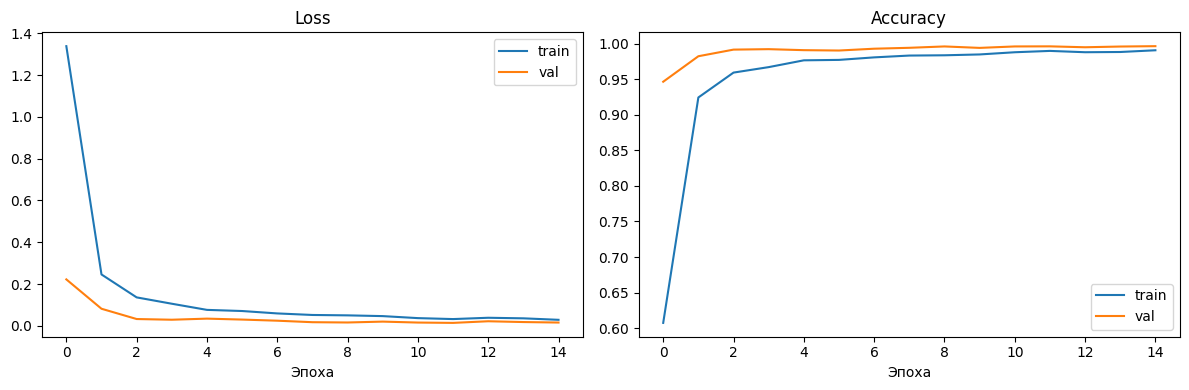

In [25]:
plot_history(gtsrb_history)

In [26]:
gtsrb_test_loss, gtsrb_test_acc = run_epoch(gtsrb_model, gtsrb_test_loader, nn.CrossEntropyLoss(), None, device)
print(f"Качество на test выборке: loss={gtsrb_test_loss:.4f}, accuracy={gtsrb_test_acc:.4f}")

Качество на test выборке: loss=0.1106, accuracy=0.9773


## Карты признаков последнего слоя

In [27]:
activation = {}


def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

Сначала CIFAR-10 - цепляем hook на последний сверточный слой (`conv3`) и прогоняем через модель одну тестовую картинку.

Форма карт признаков: torch.Size([128, 8, 8])


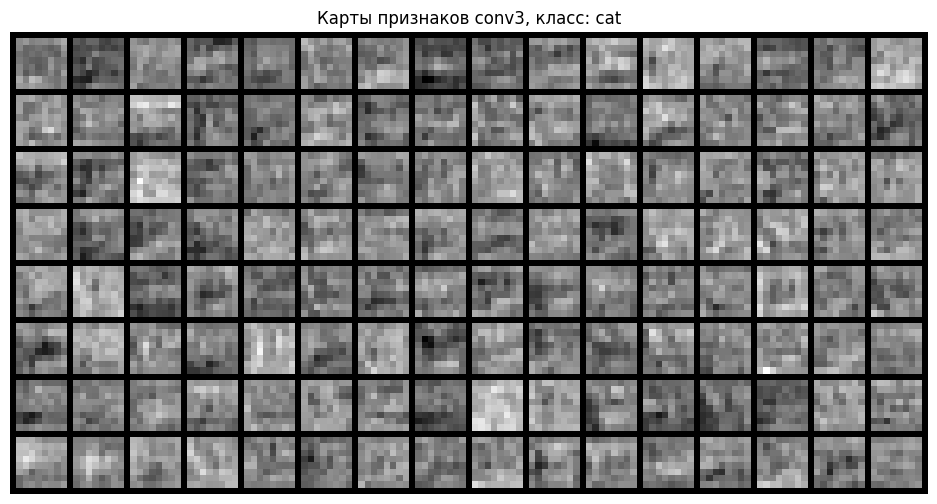

In [28]:
cifar_hook = cifar_model.conv3.register_forward_hook(get_activation("conv3"))

image, label = cifar_test[0]
image_batch = image.unsqueeze(0).to(device)

cifar_model.eval()
with torch.no_grad():
    _ = cifar_model(image_batch)

cifar_hook.remove()

cifar_feature_maps = activation["conv3"][0].cpu()
print(f"Форма карт признаков: {cifar_feature_maps.shape}")

grid = make_grid(cifar_feature_maps.unsqueeze(1), nrow=16, normalize=True, padding=1)

plt.figure(figsize=(12, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.title(f"Карты признаков conv3, класс: {cifar_classes[label]}")
plt.axis("off")
plt.show()

128 каналов, каждый - это отдельный фильтр, но на картинке с котом чётко читаемого силуэта не видно - большинство каналов выглядят довольно однородно, зернисто, без явного контура. Скорее всего дело в том, что на этой глубине (8x8, после трёх пулингов) разрешение уже совсем маленькое, а сам CIFAR-10 - это 32x32 с довольно шумным фоном, так что ждать от карт чистого силуэта животного, как в идеальных примерах, не стоило - сеть явно опирается на что-то более размазанное по всей картинке, а не на четкие границы объекта.

Форма карт признаков: torch.Size([128, 8, 8])


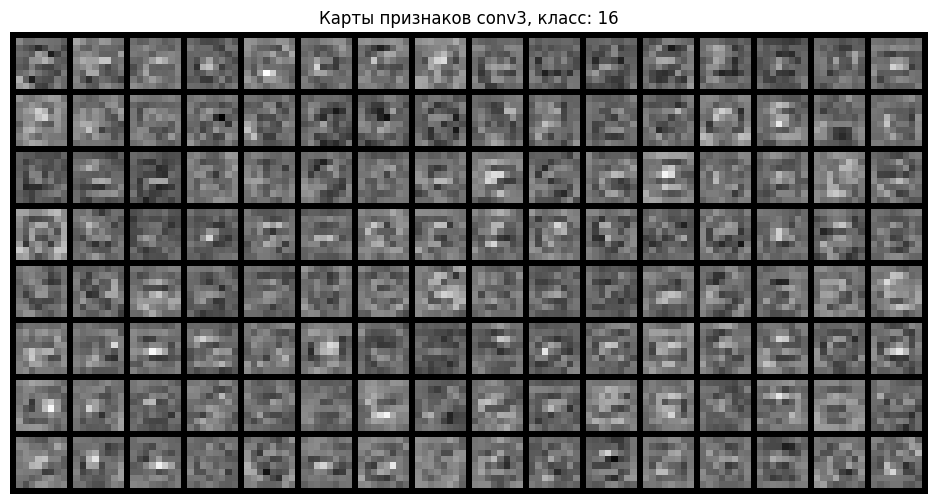

In [29]:
gtsrb_hook = gtsrb_model.conv3.register_forward_hook(get_activation("conv3"))

gtsrb_image, gtsrb_label = gtsrb_test[0]
gtsrb_image_batch = gtsrb_image.unsqueeze(0).to(device)

gtsrb_model.eval()
with torch.no_grad():
    _ = gtsrb_model(gtsrb_image_batch)

gtsrb_hook.remove()

gtsrb_feature_maps = activation["conv3"][0].cpu()
print(f"Форма карт признаков: {gtsrb_feature_maps.shape}")

grid = make_grid(gtsrb_feature_maps.unsqueeze(1), nrow=16, normalize=True, padding=1)

plt.figure(figsize=(12, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.title(f"Карты признаков conv3, класс: {gtsrb_label}")
plt.axis("off")
plt.show()

А вот на знаке видно куда отчетливее - почти на всех картах заметен круглый контур, повторяющий форму самого знака. Это логично: знаки GTSRB компактные, с четкой геометрической рамкой на почти однородном фоне, и conv3 явно цепляется именно за эту рамку, а не за детали внутри - в отличие от CIFAR-10, где фон и сам объект гораздо разнообразнее.

## Итог

В итоге получилась CNN с нуля - три блока conv+batchnorm+maxpool, где число каналов растет от 32 до 128, а на выходе две полносвязных слоя. На CIFAR-10 и на GTSRB (знаки, та же папка с Kaggle) считал train/val loss и accuracy по эпохам - графики обучения под каждым датасетом свои. Отдельно посчитал, сколько у модели параметров, и под конец заглянул в карты признаков последнего conv-слоя: часть фильтров неплохо держится за контур объекта, часть остается почти пустой на конкретной картинке - это нормально, не всем фильтрам есть за что зацепиться на одном изображении. Качество на test проверил для обоих датасетов.